In [1]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "CPU")

PyTorch: 2.11.0+cu130
GPU available: True
Device: Tesla T4


In [2]:
!git clone https://github.com/isl-org/MiDaS.git
%cd /content/MiDaS

Cloning into 'MiDaS'...
remote: Enumerating objects: 622, done.
remote: Counting objects: 100% (244/244), done.
remote: Compressing objects: 100% (106/106), done.
remote: Total 622 (delta 185), reused 138 (delta 138), pack-reused 378 (from 2)
Receiving objects: 100% (622/622), 3.44 MiB | 8.42 MiB/s, done.
Resolving deltas: 100% (249/249), done.
/content/MiDaS


In [3]:
!pip install -q "timm==0.6.13" \
    opencv-python-headless \
    matplotlib pandas scipy tqdm

In [4]:
!mkdir -p /content/MiDaS/weights

!wget -O /content/MiDaS/weights/dpt_hybrid_384.pt \
https://github.com/isl-org/MiDaS/releases/download/v3/dpt_hybrid_384.pt

--2026-10-25 06:19:22--  https://github.com/isl-org/MiDaS/releases/download/v3/dpt_hybrid_384.pt
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/193518067/d737e317-b640-48e5-82aa-9653f939e398?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-25T06%3A59%3A46Z&rscd=attachment%3B+filename%3Ddpt_hybrid_384.pt&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-10-25T05%3A59%3A44Z&ske=2026-10-25T06%3A59%3A46Z&sks=b&skv=2018-11-09&sig=N0YUcKBEPeWoJ9UqcBOVicB139P9yaDRliFOr8Fyiu4%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5MjkxMjc2MywibmJmIjoxNzkyOTA5MTYzLCJwYXRoIjoicmVsZWFzZWFzc2V0cHJvZHVjdGlvbi5ibG9iLmNv

In [5]:
from pathlib import Path

weights = Path("/content/MiDaS/weights/dpt_hybrid_384.pt")
print("Weights exist:", weights.exists())
print("Size (MB):", round(weights.stat().st_size / 1e6, 1))

Weights exist: True
Size (MB): 492.8


In [7]:

from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount("/content/drive")

# Project folder in Google Drive
ROOT = Path("/content/drive/MyDrive/BN5211_Depth_Project")

# Dataset is already extracted in Google Drive
DATA_DIR = ROOT

# Folder for saving results
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Verify dataset folders exist
for seq in ["trans_t1_a", "trans_t2_b"]:
    folder = DATA_DIR / seq

    assert folder.exists(), f"Missing folder: {folder}"

    files = [p for p in folder.rglob("*") if p.is_file()]

    print(f"{seq}: {len(files)} files found")

print("\nDataset folders located successfully!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
trans_t1_a: 306 files found
trans_t2_b: 516 files found

Dataset folders located successfully!


In [8]:
for seq in ["trans_t1_a", "trans_t2_b"]:
    folder = DATA_DIR / seq
    files = sorted(p for p in folder.rglob("*") if p.is_file())

    print("\n", seq, "—", len(files), "files")
    for p in files[:12]:
        print(p.relative_to(folder))


 trans_t1_a — 306 files
0000_color.png
0000_depth.tiff
0000_normals.tiff
0000_occlusion.png
0001_color.png
0001_depth.tiff
0001_flow.tiff
0001_normals.tiff
0001_occlusion.png
0002_color.png
0002_depth.tiff
0002_flow.tiff

 trans_t2_b — 516 files
0000_color.png
0000_depth.tiff
0000_normals.tiff
0000_occlusion.png
0001_color.png
0001_depth.tiff
0001_flow.tiff
0001_normals.tiff
0001_occlusion.png
0002_color.png
0002_depth.tiff
0002_flow.tiff


In [9]:

from pathlib import Path

def get_pairs(sequence):
    folder = DATA_DIR / sequence
    rgb_files = sorted(folder.rglob("*_color.png"))

    pairs = []

    for rgb_path in rgb_files:
        prefix = rgb_path.name.replace("_color.png", "")

        candidates = [
            rgb_path.with_name(prefix + "_depth.tiff"),
            rgb_path.with_name(prefix + "_depth.tif"),
            rgb_path.with_name(prefix + "_depth.png")
        ]

        depth_path = next(
            (p for p in candidates if p.exists()),
            None
        )

        if depth_path is not None:
            pairs.append((rgb_path, depth_path))

    return pairs

dev_pairs = get_pairs("trans_t1_a")
test_pairs = get_pairs("trans_t2_b")

print("Development pairs:", len(dev_pairs))
print("Test pairs:", len(test_pairs))

assert len(dev_pairs) == 61
assert len(test_pairs) == 103


Development pairs: 61
Test pairs: 103


In [10]:
import cv2
import numpy as np

rgb_path, depth_path = dev_pairs[0]

rgb_bgr = cv2.imread(str(rgb_path))
rgb = cv2.cvtColor(rgb_bgr, cv2.COLOR_BGR2RGB)

raw_depth = cv2.imread(
    str(depth_path),
    cv2.IMREAD_UNCHANGED
)

print("RGB shape:", rgb.shape)
print("Depth shape:", raw_depth.shape)
print("Depth dtype:", raw_depth.dtype)
print("Depth minimum:", np.min(raw_depth))
print("Depth maximum:", np.max(raw_depth))
print("Depth median:", np.median(raw_depth))

RGB shape: (1080, 1350, 3)
Depth shape: (1080, 1350)
Depth dtype: uint16
Depth minimum: 0
Depth maximum: 65535
Depth median: 11929.0


In [11]:

def load_depth(path):
    raw = cv2.imread(
        str(path),
        cv2.IMREAD_UNCHANGED
    )

    if raw is None:
        raise ValueError(f"Cannot read depth: {path}")

    if raw.ndim != 2:
        raise ValueError("Expected single-channel depth")

    if raw.dtype == np.uint16:
        # ONLY if confirmed as 0-65535 -> 0-100 mm
        depth_mm = (
            raw.astype(np.float32) * 100.0 / 65535.0
        )
    else:
        raise ValueError(
            f"Unverified TIFF format: {raw.dtype}"
        )

    return depth_mm


In [12]:
import shutil

INPUT_DIR = Path("/content/MiDaS/input_c3vd")
OUTPUT_DIR = Path("/content/MiDaS/output_c3vd")

INPUT_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

for rgb_path, _ in dev_pairs[:5]:
    shutil.copy2(rgb_path, INPUT_DIR / rgb_path.name)

print("Prepared", len(list(INPUT_DIR.glob("*.png"))), "images")

Prepared 5 images


In [13]:
%cd /content/MiDaS

!python run.py \
    --model_type dpt_hybrid_384 \
    --input_path /content/MiDaS/input_c3vd \
    --output_path /content/MiDaS/output_c3vd

/content/MiDaS
Initialize
Device: cuda
Model loaded, number of parameters = 123M
Start processing
  Processing /content/MiDaS/input_c3vd/0004_color.png (1/5)
    Input resized to 480x384 before entering the encoder
  Processing /content/MiDaS/input_c3vd/0001_color.png (2/5)
    Input resized to 480x384 before entering the encoder
  Processing /content/MiDaS/input_c3vd/0002_color.png (3/5)
    Input resized to 480x384 before entering the encoder
  Processing /content/MiDaS/input_c3vd/0003_color.png (4/5)
    Input resized to 480x384 before entering the encoder
  Processing /content/MiDaS/input_c3vd/0000_color.png (5/5)
    Input resized to 480x384 before entering the encoder
Finished


In [14]:
output_files = sorted(OUTPUT_DIR.glob("*"))

print("Generated files:")
for p in output_files:
    print(p.name)

Generated files:
0000_color-dpt_hybrid_384.pfm
0000_color-dpt_hybrid_384.png
0001_color-dpt_hybrid_384.pfm
0001_color-dpt_hybrid_384.png
0002_color-dpt_hybrid_384.pfm
0002_color-dpt_hybrid_384.png
0003_color-dpt_hybrid_384.pfm
0003_color-dpt_hybrid_384.png
0004_color-dpt_hybrid_384.pfm
0004_color-dpt_hybrid_384.png


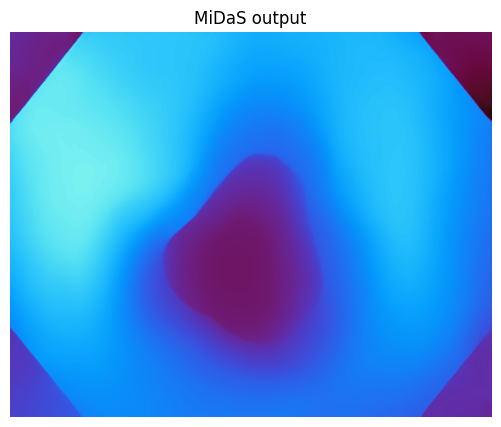

In [15]:
import matplotlib.pyplot as plt

png_files = sorted(OUTPUT_DIR.glob("*.png"))
assert png_files, "No PNG outputs found"

pred_image = cv2.imread(str(png_files[0]), cv2.IMREAD_UNCHANGED)

plt.figure(figsize=(7, 5))
plt.imshow(pred_image, cmap="magma")
plt.title("MiDaS output")
plt.axis("off")
plt.show()

In [16]:
import torch
import torch.nn.functional as F

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

midas = torch.hub.load(
    "intel-isl/MiDaS",
    "DPT_Hybrid",
    trust_repo=True
)

midas.to(device)
midas.eval()

transforms = torch.hub.load(
    "intel-isl/MiDaS",
    "transforms",
    trust_repo=True
)

transform = transforms.dpt_transform

Downloading: "https://github.com/intel-isl/MiDaS/zipball/master" to /root/.cache/torch/hub/master.zip
Downloading: "https://github.com/isl-org/MiDaS/releases/download/v3/dpt_hybrid_384.pt" to /root/.cache/torch/hub/checkpoints/dpt_hybrid_384.pt


100%|██████████| 470M/470M [00:02<00:00, 192MB/s]
Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


In [17]:
@torch.inference_mode()
def predict_midas(rgb_image):
    input_batch = transform(rgb_image).to(device)

    prediction = midas(input_batch)

    prediction = F.interpolate(
        prediction.unsqueeze(1),
        size=rgb_image.shape[:2],
        mode="bicubic",
        align_corners=False
    ).squeeze()

    return prediction.cpu().numpy().astype(np.float32)

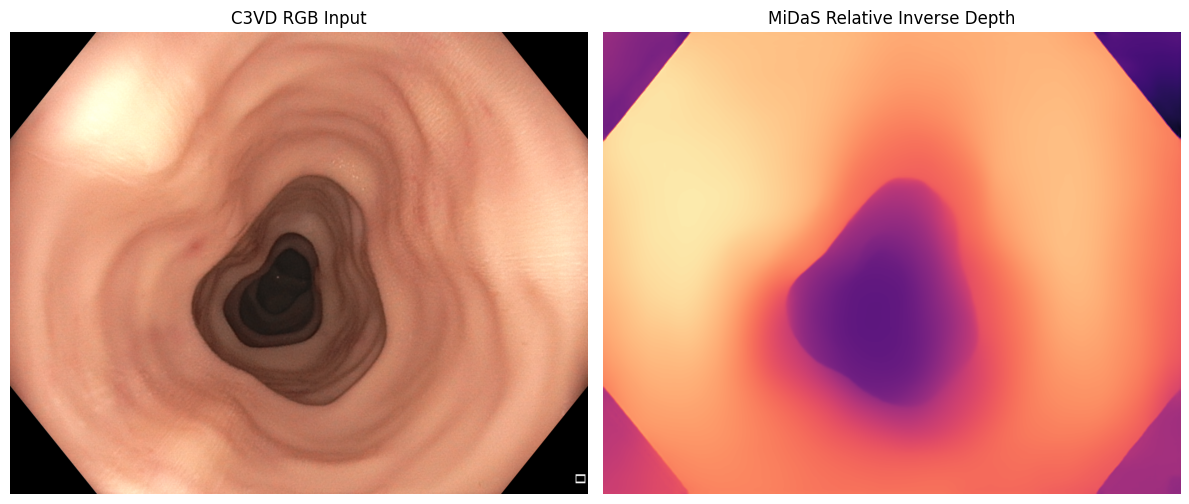

In [18]:
prediction = predict_midas(rgb)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(rgb)
axes[0].set_title("C3VD RGB Input")

axes[1].imshow(prediction, cmap="magma")
axes[1].set_title("MiDaS Relative Inverse Depth")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [19]:

def load_rgb(path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)

    if img is None:
        raise ValueError(f"Cannot read image: {path}")

    return cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )


In [20]:

from tqdm.auto import tqdm

def generate_predictions(pairs):
    predictions = []
    ground_truths = []

    for rgb_path, depth_path in tqdm(pairs):
        rgb_img = load_rgb(rgb_path)
        gt = load_depth(depth_path)

        pred = predict_midas(rgb_img)

        assert pred.shape == gt.shape

        predictions.append(pred)
        ground_truths.append(gt)

    return predictions, ground_truths

dev_preds, dev_gts = generate_predictions(dev_pairs)

print("Development predictions:", len(dev_preds))


  0%|          | 0/61 [00:00<?, ?it/s]

Development predictions: 61


In [21]:

from scipy.optimize import least_squares

rng = np.random.default_rng(42)

X, Y = [], []

for pred, gt in zip(dev_preds, dev_gts):
    valid = (
        np.isfinite(pred) &
        np.isfinite(gt) &
        (gt > 0) &
        (gt < 100)
    )

    x = pred[valid]
    y = 1.0 / gt[valid]

    if len(x) == 0:
        continue

    idx = rng.choice(
        len(x),
        size=min(5000, len(x)),
        replace=False
    )

    X.append(x[idx])
    Y.append(y[idx])

X = np.concatenate(X)
Y = np.concatenate(Y)

result = least_squares(
    lambda p: p[0] * X + p[1] - Y,
    x0=[0.001, 0.01],
    bounds=([0.0, 1e-6], [np.inf, np.inf]),
    loss="soft_l1"
)

a, b = result.x

print("Calibration scale a:", a)
print("Calibration offset b:", b)


Calibration scale a: 5.398187008032233e-05
Calibration offset b: 1.0000000000000432e-06


In [22]:

def calibrate_depth(pred, a, b):
    inverse_depth = a * pred + b

    if not np.all(np.isfinite(inverse_depth)):
        raise ValueError("Non-finite inverse depth")

    if np.any(inverse_depth <= 0):
        raise ValueError(
            "Calibration produced nonpositive inverse depth"
        )

    depth_mm = 1.0 / inverse_depth

    return depth_mm.astype(np.float32)


In [23]:

valid_depth_values = []

for gt in dev_gts:
    valid = (
        np.isfinite(gt) &
        (gt > 0) &
        (gt < 100)
    )

    valid_depth_values.append(gt[valid])

median_depth = np.median(
    np.concatenate(valid_depth_values)
)

print("Median depth:", median_depth, "mm")

def predict_baseline(shape):
    return np.full(
        shape,
        median_depth,
        dtype=np.float32
    )


Median depth: 17.25948 mm


In [24]:

def compute_metrics(gt, pred):
    assert gt.shape == pred.shape

    valid = (
        np.isfinite(gt) &
        (gt > 0) &
        (gt < 100)
    )

    gt_valid = gt[valid].astype(np.float64)
    pred_valid = pred[valid].astype(np.float64)

    if len(gt_valid) == 0:
        raise ValueError("No valid pixels")

    if not np.all(np.isfinite(pred_valid)):
        raise ValueError("Non-finite predictions")

    if np.any(pred_valid <= 0):
        raise ValueError("Nonpositive predictions")

    absrel = np.mean(
        np.abs(gt_valid - pred_valid) / gt_valid
    )

    rmse = np.sqrt(
        np.mean((gt_valid - pred_valid) ** 2)
    )

    ratio = np.maximum(
        gt_valid / pred_valid,
        pred_valid / gt_valid
    )

    delta1 = np.mean(ratio < 1.25)

    return {
        "AbsRel": float(absrel),
        "RMSE_mm": float(rmse),
        "Delta1": float(delta1)
    }


In [25]:

test_preds, test_gts = generate_predictions(test_pairs)

print("Test predictions:", len(test_preds))


  0%|          | 0/103 [00:00<?, ?it/s]

Test predictions: 103


In [26]:

import pandas as pd

records = []

for i, (pred, gt) in enumerate(
    zip(test_preds, test_gts)
):
    midas_depth = calibrate_depth(pred, a, b)

    baseline_depth = predict_baseline(gt.shape)

    midas_metrics = compute_metrics(gt, midas_depth)
    baseline_metrics = compute_metrics(gt, baseline_depth)

    records.append({
        "Frame": i,
        "Model": "MiDaS DPT-Hybrid calibrated",
        **midas_metrics
    })

    records.append({
        "Frame": i,
        "Model": "Constant median baseline",
        **baseline_metrics
    })

results_df = pd.DataFrame(records)

summary = (
    results_df
    .groupby("Model")[["AbsRel", "RMSE_mm", "Delta1"]]
    .mean()
)

print(summary)


                               AbsRel    RMSE_mm    Delta1
Model                                                     
Constant median baseline     0.549902  17.691578  0.275154
MiDaS DPT-Hybrid calibrated  0.423944  16.766549  0.218999


In [27]:

results_df.to_csv(
    RESULTS_DIR / "midas_per_frame_results.csv",
    index=False
)

summary.to_csv(
    RESULTS_DIR / "midas_summary_results.csv"
)

print("Results saved successfully")


Results saved successfully


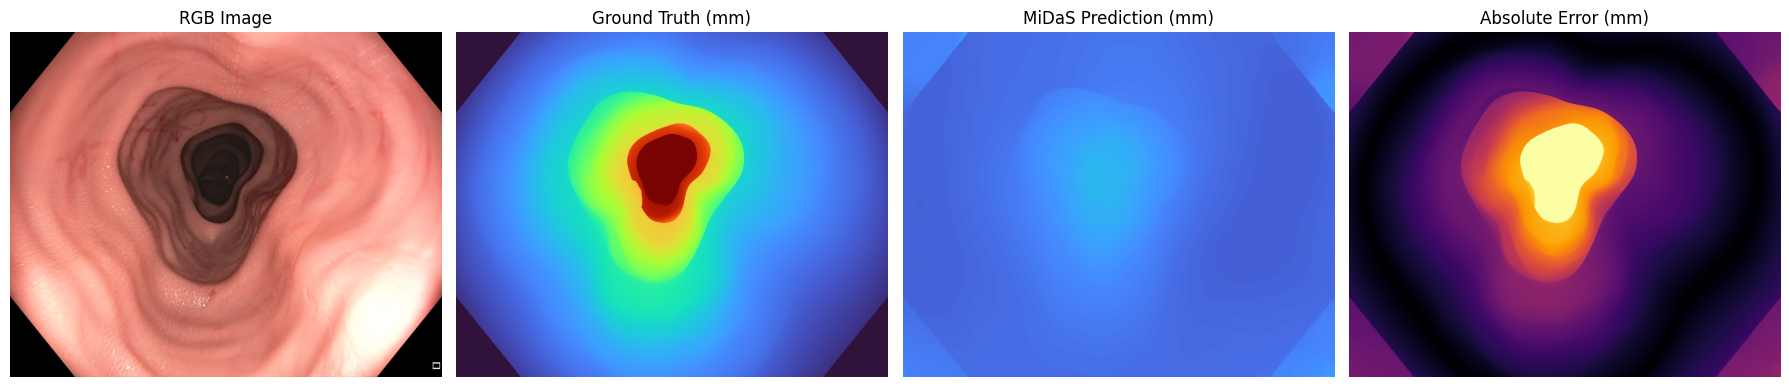

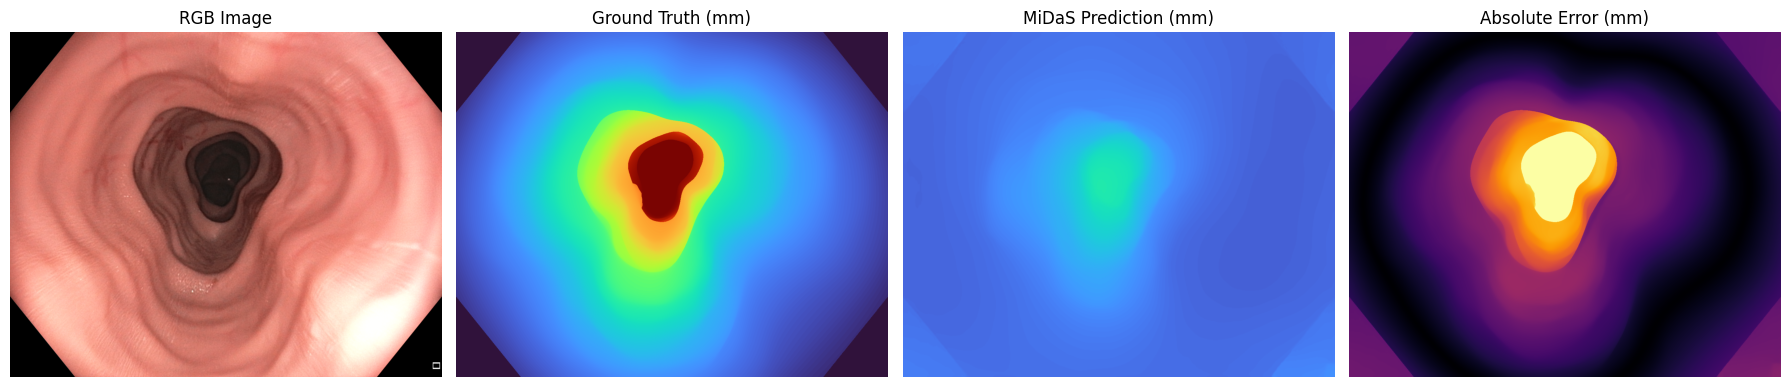

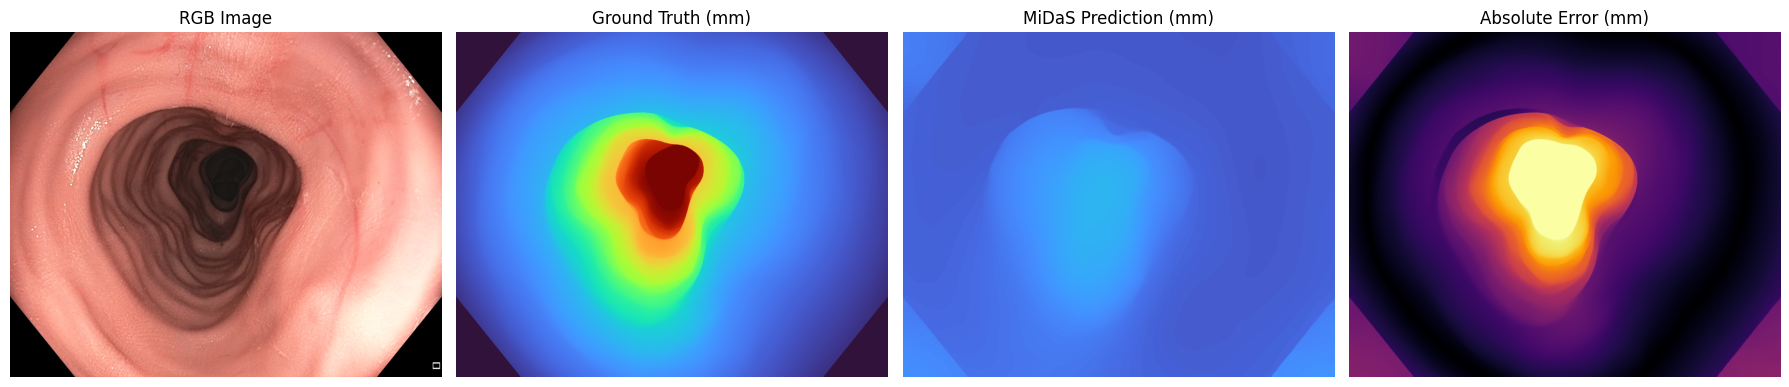

In [28]:

import matplotlib.pyplot as plt

sample_indices = [
    0,
    len(test_pairs) // 2,
    len(test_pairs) - 1
]

for i in sample_indices:
    rgb_path, _ = test_pairs[i]

    rgb_img = load_rgb(rgb_path)
    gt = test_gts[i]

    pred = calibrate_depth(test_preds[i], a, b)

    error = np.abs(gt - pred)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))

    axes[0].imshow(rgb_img)
    axes[0].set_title("RGB Image")

    axes[1].imshow(
        gt, cmap="turbo", vmin=0, vmax=100
    )
    axes[1].set_title("Ground Truth (mm)")

    axes[2].imshow(
        pred, cmap="turbo", vmin=0, vmax=100
    )
    axes[2].set_title("MiDaS Prediction (mm)")

    axes[3].imshow(
        error, cmap="inferno", vmin=0, vmax=50
    )
    axes[3].set_title("Absolute Error (mm)")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR / f"comparison_frame_{i:03d}.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()


In [29]:

import numpy as np
from scipy.optimize import lsq_linear

rng = np.random.default_rng(42)

X_parts = []
Y_parts = []

for pred, gt in zip(dev_preds, dev_gts):
    valid = (
        np.isfinite(pred) &
        np.isfinite(gt) &
        (gt > 0) &
        (gt < 100)
    )

    p = pred[valid].astype(np.float64)
    d = gt[valid].astype(np.float64)

    idx = rng.choice(
        len(p),
        size=min(5000, len(p)),
        replace=False
    )

    X_parts.append(p[idx])
    Y_parts.append(d[idx])

X = np.concatenate(X_parts)
Y = np.concatenate(Y_parts)

# Depth = intercept - slope * MiDaS output
# Constrain slope >= 0 because MiDaS predicts inverse depth
A = np.column_stack([-X, np.ones_like(X)])

fit = lsq_linear(
    A,
    Y,
    bounds=([0, 0], [np.inf, np.inf]),
    max_iter=200
)

slope, intercept = fit.x

print("Slope:", slope)
print("Intercept:", intercept)
print("Fit successful:", fit.success)


Slope: 0.05214699895037689
Intercept: 92.68961612598423
Fit successful: True


In [30]:

def calibrate_linear(pred):
    depth = intercept - slope * pred

    # Ensure positive metric depth
    depth = np.maximum(depth, 0.1)

    return depth.astype(np.float32)


In [31]:

linear_records = []

for i, (pred, gt) in enumerate(zip(test_preds, test_gts)):
    depth = calibrate_linear(pred)
    metrics = compute_metrics(gt, depth)

    linear_records.append({
        "Frame": i,
        **metrics
    })

linear_df = pd.DataFrame(linear_records)

linear_summary = linear_df[
    ["AbsRel", "RMSE_mm", "Delta1"]
].mean()

print("MiDaS + Global Linear Calibration")
print(linear_summary)


MiDaS + Global Linear Calibration
AbsRel      0.531185
RMSE_mm    11.438462
Delta1      0.282188
dtype: float64


In [32]:

comparison = pd.DataFrame({
    "Constant median": summary.loc[
        "Constant median baseline"
    ],
    "MiDaS inverse calibration": summary.loc[
        "MiDaS DPT-Hybrid calibrated"
    ],
    "MiDaS linear calibration": linear_summary
}).T

print(comparison.round(4))

comparison.to_csv(
    RESULTS_DIR / "midas_calibration_comparison.csv"
)


                           AbsRel  RMSE_mm  Delta1
Constant median            0.5499  17.6916  0.2752
MiDaS inverse calibration  0.4239  16.7665  0.2190
MiDaS linear calibration   0.5312  11.4385  0.2822


In [33]:

for name, predictions in [
    ("Development", dev_preds),
    ("Test", test_preds)
]:
    all_min = []
    all_max = []
    clipped = 0
    total = 0

    for pred in predictions:
        raw_calibrated = intercept - slope * pred

        all_min.append(np.nanmin(raw_calibrated))
        all_max.append(np.nanmax(raw_calibrated))

        clipped += np.count_nonzero(raw_calibrated < 0.1)
        total += raw_calibrated.size

    print(name)
    print("Minimum raw depth:", min(all_min))
    print("Maximum raw depth:", max(all_max))
    print("Fraction clipped:", clipped / total)
    print()


Development
Minimum raw depth: -12.130912416637273
Maximum raw depth: 80.68833713096036
Fraction clipped: 0.009608839865974049

Test
Minimum raw depth: -23.239935539590704
Maximum raw depth: 76.80546009920647
Fraction clipped: 0.12575382556234768



In [34]:

import numpy as np
import pandas as pd

def inspect_depths(depth_maps, name):
    values = []

    for gt in depth_maps:
        valid = (
            np.isfinite(gt) &
            (gt > 0) &
            (gt < 100)
        )
        values.append(gt[valid])

    all_depths = np.concatenate(values)

    print(f"\n{name}")
    print("Frames:", len(depth_maps))
    print("Valid pixels:", len(all_depths))
    print("Minimum:", np.min(all_depths))
    print("Maximum:", np.max(all_depths))
    print("Mean:", np.mean(all_depths))
    print("Median:", np.median(all_depths))
    print("Std:", np.std(all_depths))

    return all_depths

dev_values = inspect_depths(dev_gts, "Development")
test_values = inspect_depths(test_gts, "Testing")



Development
Frames: 61
Valid pixels: 80952223
Minimum: 2.2812238
Maximum: 99.998474
Mean: 22.984386
Median: 17.25948
Std: 17.404121

Testing
Frames: 103
Valid pixels: 136655314
Minimum: 2.8320744
Maximum: 99.998474
Mean: 22.85487
Median: 17.730984
Std: 16.80516


In [35]:

def valid_depth_mask(gt):
    return (
        np.isfinite(gt) &
        (gt > 0) &
        (gt < 100)
    )

def evaluate_depth(gt, pred):
    gt = np.asarray(gt, dtype=np.float64)
    pred = np.asarray(pred, dtype=np.float64)

    assert gt.shape == pred.shape

    valid = valid_depth_mask(gt)

    g = gt[valid]
    p = pred[valid]

    if len(g) == 0:
        raise ValueError("No valid pixels")

    if not np.all(np.isfinite(p)) or np.any(p <= 0):
        raise ValueError("Invalid predicted depth")

    absrel = np.mean(np.abs(g - p) / g)
    rmse = np.sqrt(np.mean((g - p) ** 2))

    delta = np.mean(
        np.maximum(g / p, p / g) < 1.25
    )

    mae = np.mean(np.abs(g - p))

    return {
        "MAE_mm": float(mae),
        "AbsRel": float(absrel),
        "RMSE_mm": float(rmse),
        "Delta1": float(delta)
    }


In [36]:

median_depth_shared = np.median(dev_values)

baseline_results = []

for gt in test_gts:
    pred = np.full_like(
        gt,
        median_depth_shared,
        dtype=np.float32
    )

    baseline_results.append(evaluate_depth(gt, pred))

baseline_df = pd.DataFrame(baseline_results)

print("Development median:", median_depth_shared)
print("\nConstant-median baseline:")
print(baseline_df.mean().round(4))


Development median: 17.25948

Constant-median baseline:
MAE_mm     11.4542
AbsRel      0.5499
RMSE_mm    17.6916
Delta1      0.2752
dtype: float64


In [37]:

inverse_results = []
linear_results = []

for pred, gt in zip(test_preds, test_gts):
    inverse_depth = calibrate_depth(pred, a, b)
    linear_depth = calibrate_linear(pred)

    inverse_results.append(
        evaluate_depth(gt, inverse_depth)
    )

    linear_results.append(
        evaluate_depth(gt, linear_depth)
    )

inverse_df = pd.DataFrame(inverse_results)
linear_df = pd.DataFrame(linear_results)

comparison = pd.DataFrame({
    "Constant median": baseline_df.mean(),
    "MiDaS inverse calibration": inverse_df.mean(),
    "MiDaS linear calibration": linear_df.mean()
}).T

print(comparison.round(4))

comparison.to_csv(
    RESULTS_DIR / "midas_standardized_comparison.csv"
)


                            MAE_mm  AbsRel  RMSE_mm  Delta1
Constant median            11.4542  0.5499  17.6916  0.2752
MiDaS inverse calibration  11.0445  0.4239  16.7665  0.2190
MiDaS linear calibration    9.1298  0.5312  11.4385  0.2822


In [38]:

def clipping_diagnostics(predictions, ground_truths):
    rows = []

    for i, (pred, gt) in enumerate(
        zip(predictions, ground_truths)
    ):
        raw_depth = intercept - slope * pred
        valid = valid_depth_mask(gt)

        clipped = raw_depth[valid] < 0.1

        rows.append({
            "Frame": i,
            "Clipped_fraction": clipped.mean(),
            "Raw_min_mm": raw_depth[valid].min(),
            "Raw_median_mm": np.median(raw_depth[valid]),
            "Raw_max_mm": raw_depth[valid].max()
        })

    return pd.DataFrame(rows)

clip_dev = clipping_diagnostics(dev_preds, dev_gts)
clip_test = clipping_diagnostics(test_preds, test_gts)

print("Development clipping:", clip_dev["Clipped_fraction"].mean())
print("Test clipping:", clip_test["Clipped_fraction"].mean())

print("\nWorst test frames:")
print(
    clip_test.sort_values(
        "Clipped_fraction", ascending=False
    ).head(10)
)


Development clipping: 0.010566222051152995
Test clipping: 0.1380378099254622

Worst test frames:
     Frame  Clipped_fraction  Raw_min_mm  Raw_median_mm  Raw_max_mm
94      94          0.449219  -12.069777       1.705510   52.518651
88      88          0.444707  -12.004084       2.478911   51.171499
93      93          0.435897  -15.195994       2.315449   51.371608
90      90          0.416627  -13.046878       2.907987   54.124676
91      91          0.411889  -11.667210       2.831349   54.435601
87      87          0.396265  -10.196610       3.725321   54.200904
86      86          0.387155  -12.096003       3.616673   54.551525
89      89          0.370625  -10.028889       4.073166   53.937843
101    101          0.359777  -10.681618       4.573957   53.826005
98      98          0.342379   -9.575079       4.478110   55.132472


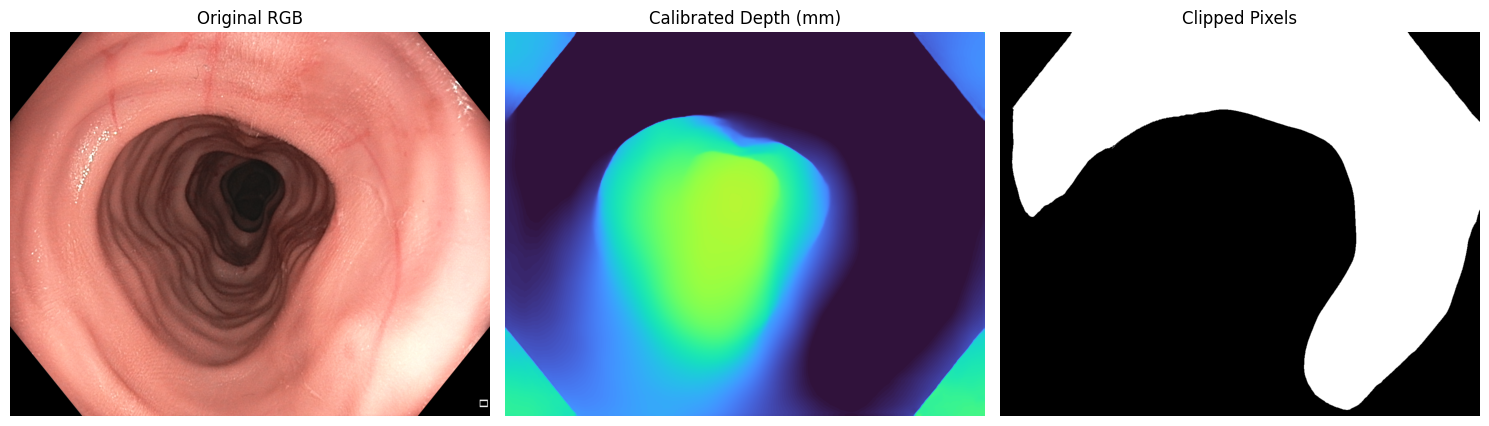

In [39]:

import matplotlib.pyplot as plt

worst_idx = int(
    clip_test.sort_values(
        "Clipped_fraction", ascending=False
    ).iloc[0]["Frame"]
)

rgb_path, _ = test_pairs[worst_idx]
rgb_img = load_rgb(rgb_path)

raw_linear = intercept - slope * test_preds[worst_idx]
clipped_mask = raw_linear < 0.1

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(rgb_img)
axes[0].set_title("Original RGB")

axes[1].imshow(
    calibrate_linear(test_preds[worst_idx]),
    cmap="turbo", vmin=0, vmax=100
)
axes[1].set_title("Calibrated Depth (mm)")

axes[2].imshow(clipped_mask, cmap="gray")
axes[2].set_title("Clipped Pixels")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [40]:

protocol = {
    "Development sequence": "trans_t1_a",
    "Test sequence": "trans_t2_b",
    "Development frames": len(dev_gts),
    "Test frames": len(test_gts),
    "Median depth (mm)": float(median_depth_shared),
    "GT valid minimum": "gt > 0",
    "GT valid maximum": "gt < 100",
    "Metric aggregation": "Mean of per-frame metrics",
    "Baseline AbsRel": float(baseline_df["AbsRel"].mean()),
    "Baseline RMSE": float(baseline_df["RMSE_mm"].mean()),
    "Baseline Delta1": float(baseline_df["Delta1"].mean())
}

protocol_df = pd.DataFrame(
    list(protocol.items()),
    columns=["Setting", "Value"]
)

print(protocol_df.to_string(index=False))

protocol_df.to_csv(
    RESULTS_DIR / "midas_evaluation_protocol.csv",
    index=False
)


             Setting                     Value
Development sequence                trans_t1_a
       Test sequence                trans_t2_b
  Development frames                        61
         Test frames                       103
   Median depth (mm)                  17.25948
    GT valid minimum                    gt > 0
    GT valid maximum                  gt < 100
  Metric aggregation Mean of per-frame metrics
     Baseline AbsRel                  0.549902
       Baseline RMSE                 17.691578
     Baseline Delta1                  0.275154
